# Loading and Displaying Data

In [ ]:
import pandas as pd

# Load the datasets
real_news = pd.read_csv('True.csv')

# Printing head and tail
print(real_news)

# Print length => rows
print("Length (rows):", len(real_news))


                                                   title  \
0      As U.S. budget fight looms, Republicans flip t...   
1      U.S. military to accept transgender recruits o...   
2      Senior U.S. Republican senator: 'Let Mr. Muell...   
3      FBI Russia probe helped by Australian diplomat...   
4      Trump wants Postal Service to charge 'much mor...   
...                                                  ...   
21412  'Fully committed' NATO backs new U.S. approach...   
21413  LexisNexis withdrew two products from Chinese ...   
21414  Minsk cultural hub becomes haven from authorities   
21415  Vatican upbeat on possibility of Pope Francis ...   
21416  Indonesia to buy $1.14 billion worth of Russia...   

                                                    text       subject  \
0      WASHINGTON (Reuters) - The head of a conservat...  politicsNews   
1      WASHINGTON (Reuters) - Transgender people will...  politicsNews   
2      WASHINGTON (Reuters) - The special counsel inv... 

In [ ]:
import pandas as pd

# Load the datasets
fake_news = pd.read_csv('Fake.csv')

# Printing head and tail
print(fake_news)

# Print length => rows
print("Length (rows):", len(fake_news))


                                                   title  \
0       Donald Trump Sends Out Embarrassing New Year’...   
1       Drunk Bragging Trump Staffer Started Russian ...   
2       Sheriff David Clarke Becomes An Internet Joke...   
3       Trump Is So Obsessed He Even Has Obama’s Name...   
4       Pope Francis Just Called Out Donald Trump Dur...   
...                                                  ...   
23476  McPain: John McCain Furious That Iran Treated ...   
23477  JUSTICE? Yahoo Settles E-mail Privacy Class-ac...   
23478  Sunnistan: US and Allied ‘Safe Zone’ Plan to T...   
23479  How to Blow $700 Million: Al Jazeera America F...   
23480  10 U.S. Navy Sailors Held by Iranian Military ...   

                                                    text      subject  \
0      Donald Trump just couldn t wish all Americans ...         News   
1      House Intelligence Committee Chairman Devin Nu...         News   
2      On Friday, it was revealed that former Milwauk...    

# Combining and Shuffling the data

In [ ]:
# Load the dataset
fake_news = pd.read_csv('Fake.csv')
real_news = pd.read_csv('True.csv')

# Combine the datasets and shuffle
fake_news['label'] = 0    # adds a column
real_news['label'] = 1

data = pd.concat([fake_news, real_news]).sample(frac=1.0)   # frac 1.0 => returns all the data (rows)

# Write the combined data to a new CSV file
data.to_csv('Combined.csv', index=False)

print("Data loaded successfully and combined CSV generated!")


Data loaded successfully and combined CSV generated!


,title,text,subject,date,label
477,"Even Back In 1993, Donald Trump Was Getting S...","In any other administration, this would be abs...",News,"August 29, 2017",0
262,House approves stop-gap government funding bill,WASHINGTON (Reuters) - The U.S. House of Repre...,politicsNews,"December 7, 2017",1
8577,McConnell calls Army captain Khan 'an American...,WASHINGTON (Reuters) - Senate Majority Leader ...,politicsNews,"July 31, 2016",1
2349,U.S. launches opioid fraud and detection unit,(Reuters) - U.S. Attorney General Jeff Session...,politicsNews,"August 2, 2017",1
158,Kentucky lawmaker a 'probable suicide' amid se...,(Reuters) - Kentucky state Representative Dan ...,politicsNews,"December 14, 2017",1
...,...,...,...,...,...
4361,Trump says progress made in U.S.-China relatio...,"PALM BEACH, Fla. (Reuters) - U.S. President Do...",politicsNews,"April 7, 2017",1
16280,NATO says Catalonia issue domestic matter to b...,BRUSSELS (Reuters) - Spain remains an importan...,worldnews,"October 27, 2017",1
12748,Venezuela's chronic shortages give rise to 'me...,"SAN CRISTOBAL/MARACAIBO, Venezuela (Reuters) -...",worldnews,"December 8, 2017",1
10090,Trump predicts 'very massive recession' in U.S.,MILWAUKEE (Reuters) - Republican presidential ...,politicsNews,"April 2, 2016",1


# Preprocess Function

In [ ]:
import re
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

def preprocess_text(text):
    # Replace characters that are not between a to z or A to Z with whitespace
    text = re.sub('[^a-zA-Z]', ' ', text)

    # Convert all characters into lowercase
    text = text.lower()

    # Remove inflectional morphemes like "ed", "est", "s", and "ing" from their token stem
    text = [stemmer.stem(word) for word in text.split()]

    # Join the processed words back into a single string
    text = ' '.join(text)

    return text


# Training the Model


In [ ]:
import tensorflow as tf
from transformers import BertTokenizer, TFBertForSequenceClassification

# Check if GPU is available
if tf.test.is_gpu_available():
    device_name = tf.test.gpu_device_name()
else:
    device_name = 'CPU:0'
print('Using device:', device_name)

# Load the dataset
data = pd.read_csv('Combined.csv')

# Preprocess the text using the preprocessing function
print("\nPreprocessing data...")

data['title_preprocessed'] = data['title'].apply(preprocess_text)

# Split the dataset into train, validation, and test sets
train_ratio = 0.64
val_ratio = 0.16
test_ratio = 0.2

print("\nSplitting Data...")

train_data = data.sample(frac=train_ratio, random_state=42)
remaining_data = data.drop(train_data.index)

val_data = remaining_data.sample(frac=val_ratio/(val_ratio+test_ratio), random_state=42)
test_data = remaining_data.drop(val_data.index)

# Initialize BERT tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# Tokenize the titles and convert them into BERT input tensors
print("\nTokenizing and Converting...")

train_inputs = tokenizer(list(train_data['title_preprocessed']), truncation=True, padding='max_length', max_length=42, return_tensors='tf')
val_inputs = tokenizer(list(val_data['title_preprocessed']), truncation=True, padding='max_length', max_length=42, return_tensors='tf')
test_inputs = tokenizer(list(test_data['title_preprocessed']), truncation=True, padding='max_length', max_length=42, return_tensors='tf')

# Convert the labels into TensorFlow tensors
train_labels = tf.convert_to_tensor(list(train_data['label']))
val_labels = tf.convert_to_tensor(list(val_data['label']))
test_labels = tf.convert_to_tensor(list(test_data['label']))

# Extract token tensors, segment tensors, and mask tensors from the BERT inputs
train_token_tensors = train_inputs['input_ids']
train_segment_tensors = train_inputs['token_type_ids']
train_mask_tensors = train_inputs['attention_mask']

val_token_tensors = val_inputs['input_ids']
val_segment_tensors = val_inputs['token_type_ids']
val_mask_tensors = val_inputs['attention_mask']

test_token_tensors = test_inputs['input_ids']
test_segment_tensors = test_inputs['token_type_ids']
test_mask_tensors = test_inputs['attention_mask']

# Build the BERT model
model = TFBertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)

# Compile the model
print("\nCompiling Model...")

optimizer = tf.keras.optimizers.Adam(learning_rate=2e-5)
loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
metric = tf.keras.metrics.SparseCategoricalAccuracy('accuracy')

model.compile(optimizer=optimizer, loss=loss, metrics=[metric])

# Train the BERT model
print("\nTraining Model...")

batch_size = 64
num_epochs = 3

history = model.fit([train_token_tensors, train_segment_tensors, train_mask_tensors], train_labels, batch_size=batch_size, epochs=num_epochs, validation_data=([val_token_tensors, val_segment_tensors, val_mask_tensors], val_labels))

# Save the trained model
print("\nSaving Model...")

model.save_pretrained('/content/bertv3_model')



Using device: /device:GPU:0

Preprocessing data...

Splitting Data...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]


Tokenizing and Converting...


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

All PyTorch model weights were used when initializing TFBertForSequenceClassification.

Some weights or buffers of the TF 2.0 model TFBertForSequenceClassification were not initialized from the PyTorch model and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Compiling Model...

Training Model...
Epoch 1/3
449/449 [==============================] - 323s 594ms/step - loss: 0.1697 - accuracy: 0.9373 - val_loss: 0.1011 - val_accuracy: 0.9596
Epoch 2/3
449/449 [==============================] - 287s 639ms/step - loss: 0.0773 - accuracy: 0.9734 - val_loss: 0.0816 - val_accuracy: 0.9702
Epoch 3/3
449/449 [==============================] - 266s 592ms/step - loss: 0.0452 - accuracy: 0.9849 - val_loss: 0.0841 - val_accuracy: 0.9722

Saving Model...


# Validation

In [ ]:
# Evaluate the model on the test set
loss, accuracy = model.evaluate([test_token_tensors, test_segment_tensors, test_mask_tensors], test_labels, batch_size=batch_size)
print(f'Test loss: {loss * 100:.3f}%')
print(f'Test accuracy: {accuracy * 100:.3f}%')

141/141 [==============================] - 25s 175ms/step - loss: 0.0796 - accuracy: 0.9745
Test loss: 7.963%
Test accuracy: 97.450%


141/141 [==============================] - 26s 181ms/step

Classification Report:

              precision    recall  f1-score   support

        Fake       0.97      0.98      0.98      4659
        Real       0.97      0.97      0.97      4320

    accuracy                           0.97      8979
   macro avg       0.97      0.97      0.97      8979
weighted avg       0.97      0.97      0.97      8979


Confusion Matrix:

[[4548  111]
 [ 118 4202]]


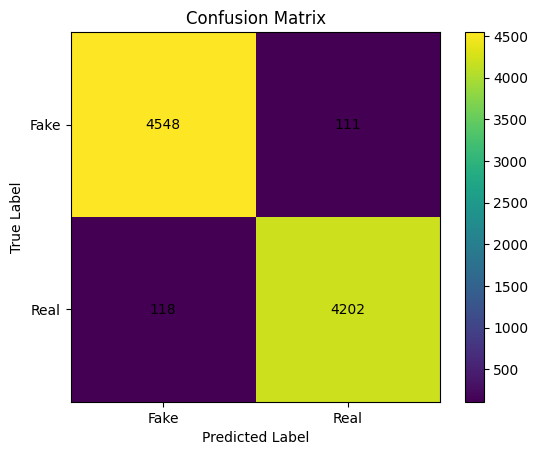


AUC Score: 0.9969


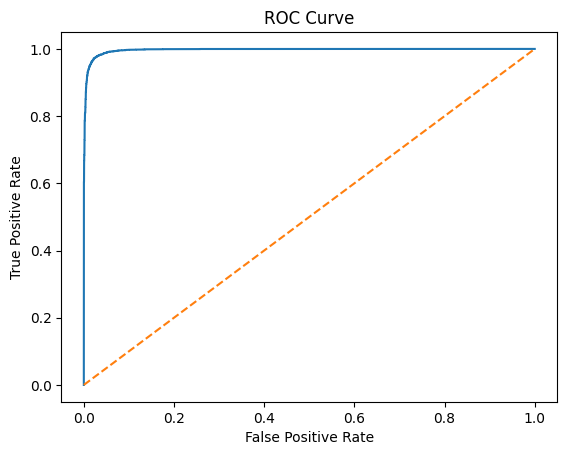

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Get model outputs
outputs = model.predict(
    [test_token_tensors, test_segment_tensors, test_mask_tensors],
    batch_size=batch_size
)

logits = outputs.logits

# Apply softmax
probs = tf.nn.softmax(logits, axis=1).numpy()

# Predicted labels
y_pred = np.argmax(probs, axis=1)

# True labels
y_true = test_labels.numpy()

# -------------------------------
# 1️⃣ Classification Report
# -------------------------------
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=["Fake", "Real"]))

# -------------------------------
# 2️⃣ Confusion Matrix
# -------------------------------
cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:\n")
print(cm)

plt.figure()
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks([0,1], ["Fake", "Real"])
plt.yticks([0,1], ["Fake", "Real"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

# -------------------------------
# 3️⃣ ROC Curve + AUC
# -------------------------------

# Use probability of class 1 (Real)
y_probs = probs[:, 1]

fpr, tpr, thresholds = roc_curve(y_true, y_probs)
roc_auc = auc(fpr, tpr)

print(f"\nAUC Score: {roc_auc:.4f}")

plt.figure()
plt.plot(fpr, tpr)
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

# Using the Model to predict

In [ ]:
from transformers import BertTokenizer, TFBertForSequenceClassification
import tensorflow as tf

# Load the saved model
model = TFBertForSequenceClassification.from_pretrained('/content/bertv3_model')

# Initialize the tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# Example input text
input_text = input("\n\nEnter News Title: ")

# Preprocess the input text
preprocessed_text = preprocess_text(input_text)

print("Preprocessed Text:", preprocessed_text)

# Tokenize the preprocessed text
inputs = tokenizer(preprocessed_text, truncation=True, padding='max_length', max_length=42, return_tensors='tf')

# Extract input tensors
token_tensors = inputs['input_ids']
segment_tensors = inputs['token_type_ids']
mask_tensors = inputs['attention_mask']

# Make predictions
predictions = model.predict([token_tensors, segment_tensors, mask_tensors])
logits = predictions.logits[0]
probabilities = tf.nn.softmax(logits)
predicted_label = tf.argmax(probabilities)

# Print the predicted label and probabilities
if predicted_label == 0:
    print("\n*-*-Fake News-*-*")
else:
    print("\n*-*-Real News-*-*")

print("\nProbability of being fake: {:.2%}".format(probabilities[0]))
print("Probability of being real: {:.2%}".format(probabilities[1]))


Some layers from the model checkpoint at /content/bertv3_model were not used when initializing TFBertForSequenceClassification: ['dropout_37']
- This IS expected if you are initializing TFBertForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFBertForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
All the layers of TFBertForSequenceClassification were initialized from the model checkpoint at /content/bertv3_model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFBertForSequenceClassification for predictions without further training.




Enter News Title: Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’
Preprocessed Text: sheriff david clark becom an internet joke for threaten to poke peopl in the eye
1/1 [==============================] - 3s 3s/step

*-*-Fake News-*-*

Probability of being fake: 99.95%
Probability of being real: 0.05%


In [ ]:
!pip uninstall -y transformers tensorflow keras sentence-transformers
!pip install tensorflow==2.19.1
!pip install transformers==4.41.2

Found existing installation: transformers 5.0.0
Uninstalling transformers-5.0.0:
  Successfully uninstalled transformers-5.0.0
Found existing installation: tensorflow 2.19.0
Uninstalling tensorflow-2.19.0:
  Successfully uninstalled tensorflow-2.19.0
Found existing installation: keras 3.10.0
Uninstalling keras-3.10.0:
  Successfully uninstalled keras-3.10.0
Found existing installation: sentence-transformers 5.2.3
Uninstalling sentence-transformers-5.2.3:
  Successfully uninstalled sentence-transformers-5.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 645.0/645.0 MB ? eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 75.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-decision-forests 1.12.0 requires tensorflow==2.19.0, but you have tensorflow 2.19.1 which is incompatible.


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 99.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 94.4 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.4.1
    Uninstalling huggingface_hub-1.4.1:
      Successfully uninstalled huggingface_hub-1.4.1
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.22.2
    Uninstalling tokenizers-0.22.2:
      Successfully uninstalled tokenizers-0.22.2
